In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Reproducibility
np.random.seed(42)

# Number of records
n = 5000

# Warehouse information
warehouses = [
    "Kolkata",
    "Delhi",
    "Mumbai",
    "Bangalore",
    "Chennai",
    "Hyderabad",
    "Pune",
    "Ahmedabad"
]

# Product information
products = [
    "Laptop",
    "Mobile",
    "Headphone",
    "Smartwatch",
    "Tablet",
    "Keyboard",
    "Mouse",
    "Monitor",
    "Printer",
    "Camera"
]

# Supplier information
suppliers = [
    "TechSupply",
    "GlobalElectro",
    "PrimeDistributors",
    "SmartSource",
    "ElectroHub"
]

# Product categories
product_category = {
    "Laptop": "Electronics",
    "Mobile": "Electronics",
    "Headphone": "Accessories",
    "Smartwatch": "Accessories",
    "Tablet": "Electronics",
    "Keyboard": "Accessories",
    "Mouse": "Accessories",
    "Monitor": "Electronics",
    "Printer": "Electronics",
    "Camera": "Electronics"
}

# Product prices
product_price = {
    "Laptop": 65000,
    "Mobile": 25000,
    "Headphone": 2500,
    "Smartwatch": 6000,
    "Tablet": 22000,
    "Keyboard": 1800,
    "Mouse": 900,
    "Monitor": 15000,
    "Printer": 12000,
    "Camera": 45000
}

# Generate dates
dates = pd.date_range(
    start="2025-01-01",
    end="2026-12-31",
    periods=n
)

# Create the dataset
df = pd.DataFrame({
    "Record_ID": range(10001, 10001 + n),

    "Date": dates,

    "Warehouse": np.random.choice(
        warehouses,
        n
    ),

    "Product": np.random.choice(
        products,
        n
    ),

    "Supplier": np.random.choice(
        suppliers,
        n
    ),

    "Current_Stock": np.random.randint(
        20,
        500,
        n
    ),

    "Units_Sold": np.random.randint(
        5,
        150,
        n
    ),

    "Previous_Demand": np.random.randint(
        10,
        180,
        n
    ),

    "Discount_Percent": np.random.choice(
        [0, 5, 10, 15, 20, 25],
        n,
        p=[0.20, 0.20, 0.25, 0.20, 0.10, 0.05]
    ),

    "Lead_Time_Days": np.random.randint(
        1,
        15,
        n
    ),

    "Delivery_Days": np.random.randint(
        1,
        8,
        n
    ),

    "Customer_Rating": np.clip(
        np.random.normal(
            4.0,
            0.6,
            n
        ),
        1,
        5
    )
})


# Add category
df["Category"] = df["Product"].map(
    product_category
)

# Add product price
df["Unit_Price"] = df["Product"].map(
    product_price
)

# Round customer ratings
df["Customer_Rating"] = df[
    "Customer_Rating"
].round(2)

# Add time-related features
df["Month"] = df["Date"].dt.month
df["Day_of_Week"] = df["Date"].dt.dayofweek


# --------------------------------------------------
# Generate Demand
# --------------------------------------------------

base_demand = (
    df["Previous_Demand"] * 0.45
    + df["Units_Sold"] * 0.35
)

discount_effect = (
    df["Discount_Percent"] * 1.2
)

rating_effect = (
    df["Customer_Rating"] * 4
)

lead_time_effect = (
    df["Lead_Time_Days"] * 0.8
)

# Higher demand during October, November and December
seasonal_effect = np.where(
    df["Month"].isin([10, 11, 12]),
    20,
    0
)

# Random variation
noise = np.random.normal(
    0,
    12,
    n
)


df["Demand"] = (
    base_demand
    + discount_effect
    + rating_effect
    + seasonal_effect
    - lead_time_effect
    + noise
)

# Demand cannot be negative
df["Demand"] = (
    df["Demand"]
    .clip(lower=1)
    .round()
    .astype(int)
)


print("Warehouse dataset created successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

Warehouse dataset created successfully!
Dataset shape: (5000, 17)

First 5 records:


,Record_ID,Date,Warehouse,Product,Supplier,Current_Stock,Units_Sold,Previous_Demand,Discount_Percent,Lead_Time_Days,Delivery_Days,Customer_Rating,Category,Unit_Price,Month,Day_of_Week,Demand
0,10001,2025-01-01 00:00:00.000000000,Pune,Headphone,ElectroHub,113,91,80,0,12,6,3.31,Accessories,2500,1,2,61
1,10002,2025-01-01 03:29:59.639927985,Bangalore,Smartwatch,SmartSource,388,52,69,20,11,1,3.58,Accessories,6000,1,2,72
2,10003,2025-01-01 06:59:59.279855971,Chennai,Mouse,TechSupply,382,92,83,10,5,7,3.46,Accessories,900,1,2,76
3,10004,2025-01-01 10:29:58.919783956,Pune,Headphone,GlobalElectro,395,72,90,10,2,5,4.49,Accessories,2500,1,2,88
4,10005,2025-01-01 13:59:58.559711942,Mumbai,Printer,TechSupply,205,105,148,10,10,4,4.08,Electronics,12000,1,2,130


In [ ]:
print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\nShape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

DATASET INFORMATION

Shape:
(5000, 17)

Column Names:
['Record_ID', 'Date', 'Warehouse', 'Product', 'Supplier', 'Current_Stock', 'Units_Sold', 'Previous_Demand', 'Discount_Percent', 'Lead_Time_Days', 'Delivery_Days', 'Customer_Rating', 'Category', 'Unit_Price', 'Month', 'Day_of_Week', 'Demand']

Data Types:
Record_ID                    int64
Date                datetime64[ns]
Warehouse                   object
Product                     object
Supplier                    object
Current_Stock                int64
Units_Sold                   int64
Previous_Demand              int64
Discount_Percent             int64
Lead_Time_Days               int64
Delivery_Days                int64
Customer_Rating            float64
Category                    object
Unit_Price                   int64
Month                        int32
Day_of_Week                  int32
Demand                       int64
dtype: object

Missing Values:
Record_ID           0
Date                0
Warehouse           0

In [ ]:
print("=" * 60)
print("STATISTICAL SUMMARY")
print("=" * 60)

display(df.describe().T)

STATISTICAL SUMMARY


,count,mean,min,25%,50%,75%,max,std
Record_ID,5000.0,12500.5,10001.0,11250.75,12500.5,13750.25,15000.0,1443.520003
Date,5000,2025-12-31 12:00:00,2025-01-01 00:00:00,2025-07-02 06:00:00,2025-12-31 12:00:00,2026-07-01 18:00:00,2026-12-31 00:00:00,NaN
Current_Stock,5000.0,258.7316,20.0,139.0,261.0,378.0,499.0,138.312331
Units_Sold,5000.0,77.6328,5.0,42.0,77.0,114.0,149.0,41.8339
Previous_Demand,5000.0,94.2268,10.0,51.0,94.0,137.0,179.0,48.830653
Discount_Percent,5000.0,9.847,0.0,5.0,10.0,15.0,25.0,7.216094
Lead_Time_Days,5000.0,7.57,1.0,4.0,8.0,11.0,14.0,3.997036
Delivery_Days,5000.0,4.0272,1.0,2.0,4.0,6.0,7.0,2.011882
Customer_Rating,5000.0,3.979076,1.84,3.59,3.99,4.41,5.0,0.583984
Unit_Price,5000.0,19523.14,900.0,2500.0,12000.0,25000.0,65000.0,20003.968464


In [ ]:
print("=" * 60)
print("CATEGORICAL DATA DISTRIBUTION")
print("=" * 60)

print("\nWarehouse Distribution:")
print(df["Warehouse"].value_counts())

print("\nProduct Distribution:")
print(df["Product"].value_counts())

print("\nCategory Distribution:")
print(df["Category"].value_counts())

print("\nSupplier Distribution:")
print(df["Supplier"].value_counts())

CATEGORICAL DATA DISTRIBUTION

Warehouse Distribution:
Warehouse
Bangalore    657
Chennai      651
Kolkata      644
Hyderabad    628
Delhi        612
Mumbai       608
Pune         601
Ahmedabad    599
Name: count, dtype: int64

Product Distribution:
Product
Keyboard      533
Mouse         532
Camera        532
Mobile        508
Laptop        493
Monitor       485
Smartwatch    483
Headphone     483
Printer       481
Tablet        470
Name: count, dtype: int64

Category Distribution:
Category
Electronics    2969
Accessories    2031
Name: count, dtype: int64

Supplier Distribution:
Supplier
ElectroHub           1036
TechSupply           1024
SmartSource           996
GlobalElectro         988
PrimeDistributors     956
Name: count, dtype: int64


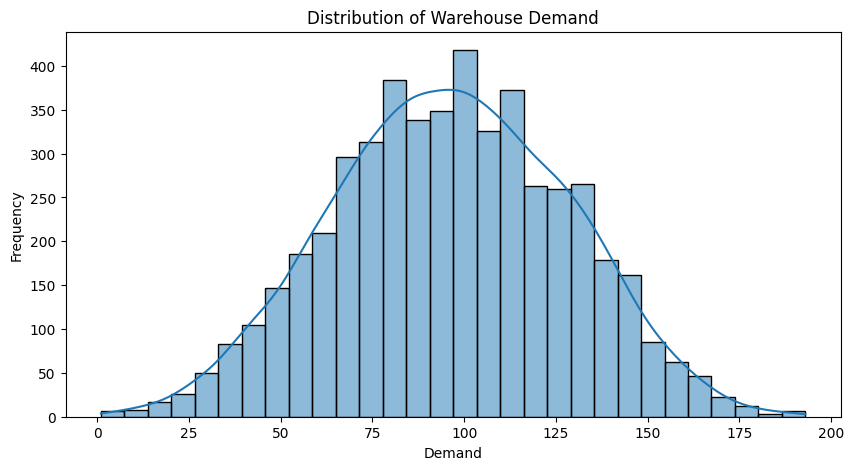

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Demand"],
    bins=30,
    kde=True
)

plt.title("Distribution of Warehouse Demand")
plt.xlabel("Demand")
plt.ylabel("Frequency")

plt.show()

Total Demand by Product:
Product
Mouse         51964
Keyboard      51167
Camera        50731
Mobile        48464
Laptop        47661
Monitor       46770
Printer       46670
Headphone     46289
Smartwatch    46257
Tablet        44976
Name: Demand, dtype: int64


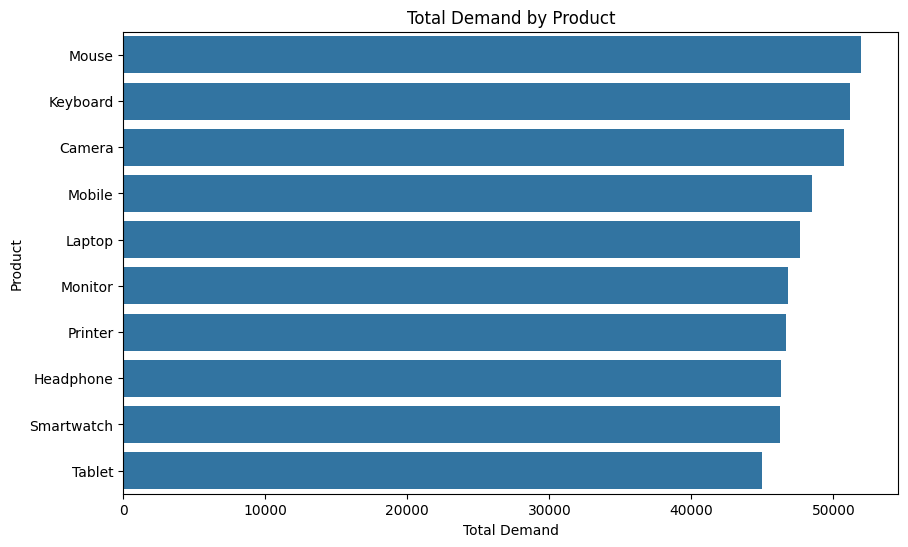

In [ ]:
product_demand = (
    df.groupby("Product")["Demand"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Demand by Product:")
print(product_demand)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=product_demand.values,
    y=product_demand.index
)

plt.title("Total Demand by Product")
plt.xlabel("Total Demand")
plt.ylabel("Product")

plt.show()

Total Demand by Warehouse:
Warehouse
Chennai      63091
Kolkata      62043
Bangalore    61981
Delhi        60340
Hyderabad    60300
Mumbai       59360
Pune         57220
Ahmedabad    56614
Name: Demand, dtype: int64


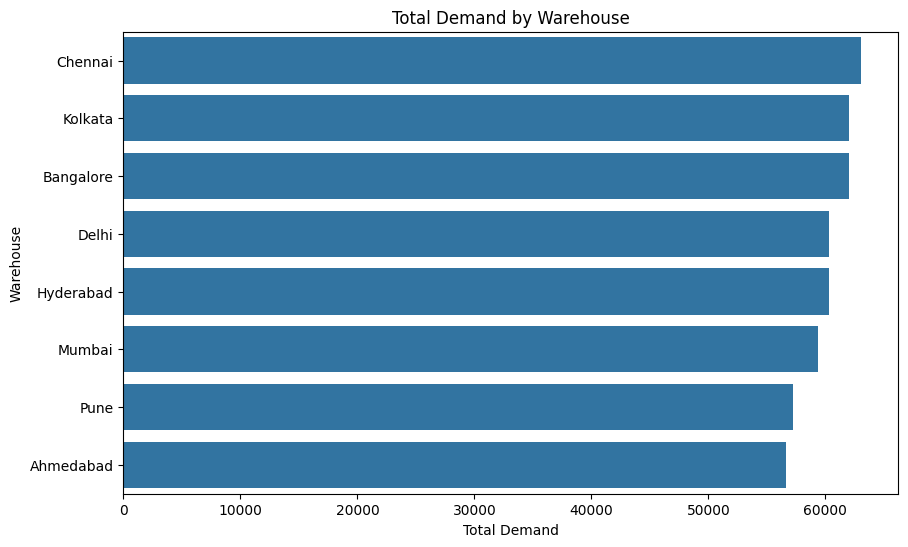

In [ ]:
warehouse_demand = (
    df.groupby("Warehouse")["Demand"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Demand by Warehouse:")
print(warehouse_demand)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=warehouse_demand.values,
    y=warehouse_demand.index
)

plt.title("Total Demand by Warehouse")
plt.xlabel("Total Demand")
plt.ylabel("Warehouse")

plt.show()

Total Demand by Category:
Category
Electronics    285272
Accessories    195677
Name: Demand, dtype: int64


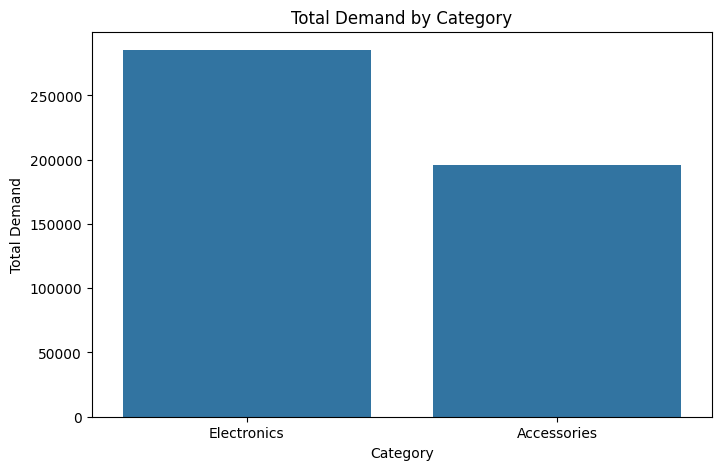

In [ ]:
category_demand = (
    df.groupby("Category")["Demand"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Demand by Category:")
print(category_demand)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_demand.index,
    y=category_demand.values
)

plt.title("Total Demand by Category")
plt.xlabel("Category")
plt.ylabel("Total Demand")

plt.show()

Monthly Demand:
Month
1     38498
2     34631
3     39250
4     38135
5     38998
6     37444
7     37455
8     38712
9     38085
10    46563
11    46784
12    46394
Name: Demand, dtype: int64


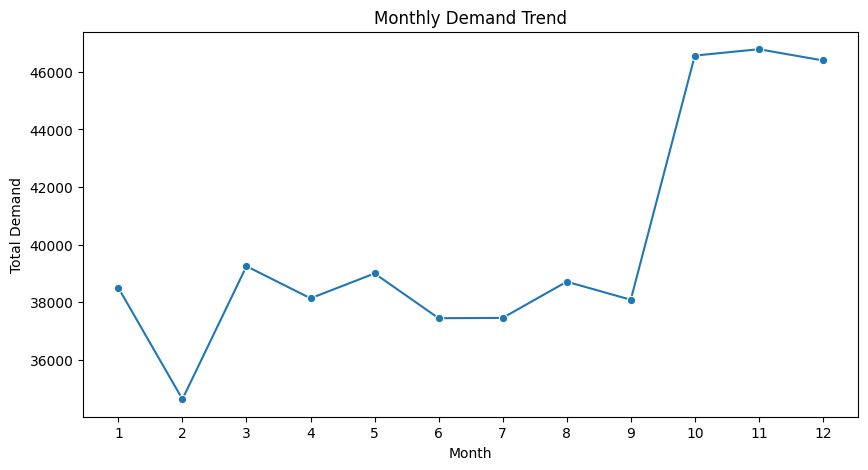

In [ ]:
monthly_demand = (
    df.groupby("Month")["Demand"]
    .sum()
)

print("Monthly Demand:")
print(monthly_demand)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_demand.index,
    y=monthly_demand.values,
    marker="o"
)

plt.title("Monthly Demand Trend")
plt.xlabel("Month")
plt.ylabel("Total Demand")

plt.xticks(range(1, 13))

plt.show()

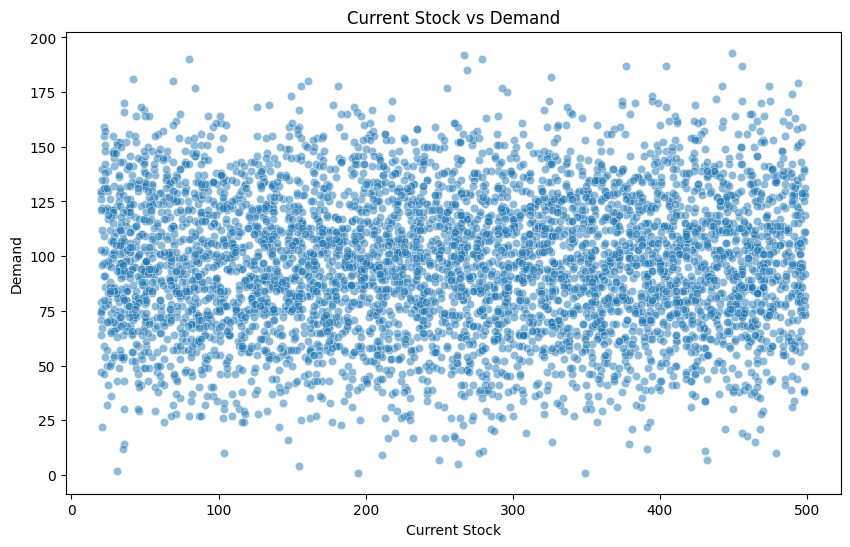

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Current_Stock",
    y="Demand",
    alpha=0.5
)

plt.title("Current Stock vs Demand")
plt.xlabel("Current Stock")
plt.ylabel("Demand")

plt.show()

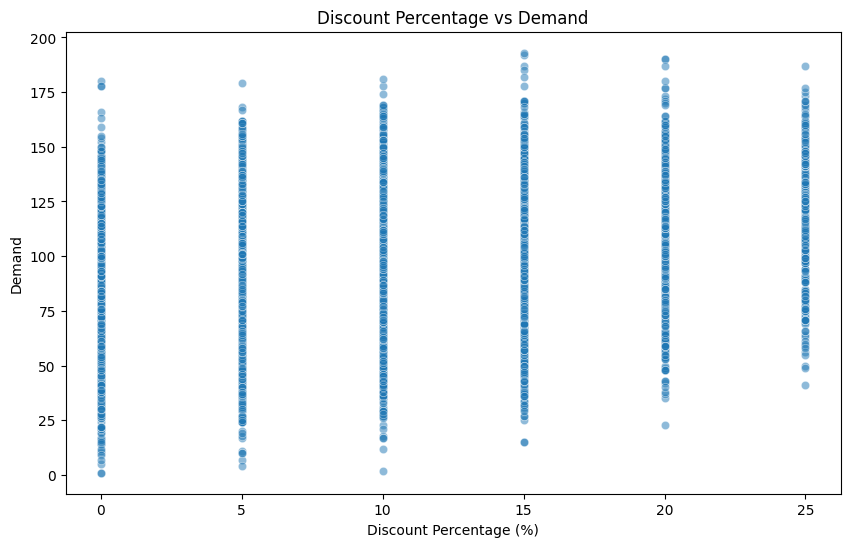

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount_Percent",
    y="Demand",
    alpha=0.5
)

plt.title("Discount Percentage vs Demand")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Demand")

plt.show()

Total Demand by Supplier:
Supplier
ElectroHub           99229
TechSupply           99157
SmartSource          96139
GlobalElectro        94631
PrimeDistributors    91793
Name: Demand, dtype: int64


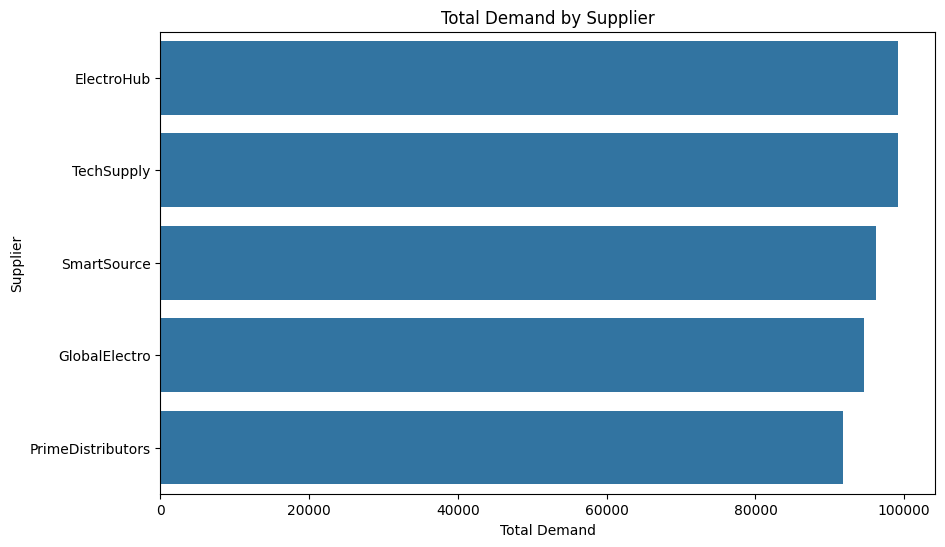

In [ ]:
supplier_demand = (
    df.groupby("Supplier")["Demand"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Demand by Supplier:")
print(supplier_demand)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=supplier_demand.values,
    y=supplier_demand.index
)

plt.title("Total Demand by Supplier")
plt.xlabel("Total Demand")
plt.ylabel("Supplier")

plt.show()

In [ ]:
# Target variable
y = df["Demand"]

# Features
X = df.drop(
    columns=["Demand"]
)

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features (X):
['Record_ID', 'Date', 'Warehouse', 'Product', 'Supplier', 'Current_Stock', 'Units_Sold', 'Previous_Demand', 'Discount_Percent', 'Lead_Time_Days', 'Delivery_Days', 'Customer_Rating', 'Category', 'Unit_Price', 'Month', 'Day_of_Week']

Target (y):
Demand

Feature shape: (5000, 16)
Target shape: (5000,)


In [ ]:
# Remove columns that are not useful as direct model features
X = df.drop(
    columns=[
        "Demand",
        "Record_ID",
        "Date"
    ]
)

y = df["Demand"]

print("Final feature columns:")
print(X.columns.tolist())

print("\nNumber of features:", X.shape[1])
print("Number of records:", X.shape[0])

Final feature columns:
['Warehouse', 'Product', 'Supplier', 'Current_Stock', 'Units_Sold', 'Previous_Demand', 'Discount_Percent', 'Lead_Time_Days', 'Delivery_Days', 'Customer_Rating', 'Category', 'Unit_Price', 'Month', 'Day_of_Week']

Number of features: 14
Number of records: 5000


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training data:
X_train: (4000, 14)
y_train: (4000,)

Testing data:
X_test: (1000, 14)
y_test: (1000,)


In [ ]:
categorical_features = [
    "Warehouse",
    "Product",
    "Supplier",
    "Category"
]

numerical_features = [
    "Current_Stock",
    "Units_Sold",
    "Previous_Demand",
    "Discount_Percent",
    "Lead_Time_Days",
    "Delivery_Days",
    "Customer_Rating",
    "Unit_Price",
    "Month",
    "Day_of_Week"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTotal categorical features:", len(categorical_features))
print("Total numerical features:", len(numerical_features))

Categorical features:
['Warehouse', 'Product', 'Supplier', 'Category']

Numerical features:
['Current_Stock', 'Units_Sold', 'Previous_Demand', 'Discount_Percent', 'Lead_Time_Days', 'Delivery_Days', 'Customer_Rating', 'Unit_Price', 'Month', 'Day_of_Week']

Total categorical features: 4
Total numerical features: 10


In [ ]:
# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)


# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)


print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
# Create the Random Forest model
random_forest = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)


# Combine preprocessing and model
model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "regressor",
            random_forest
        )
    ]
)


print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [ ]:
print("Training Random Forest model...")

model.fit(
    X_train,
    y_train
)

print("Model training completed successfully!")

Training Random Forest model...
Model training completed successfully!


In [ ]:

y_pred = model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 actual demand values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted demand values:")
print(np.round(y_pred[:10], 2))

Predictions generated successfully!

First 10 actual demand values:
[105  96 103  65  73  72  42  83 133  72]

First 10 predicted demand values:
[100.76 100.34 124.3   47.52  88.92  68.13  55.91  96.3  123.6   48.14]


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-" * 30)
print(f"MAE : {mae:.2f}")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.4f}")

Model Evaluation
------------------------------
MAE : 10.49
MSE : 169.86
RMSE: 13.03
R²  : 0.8283


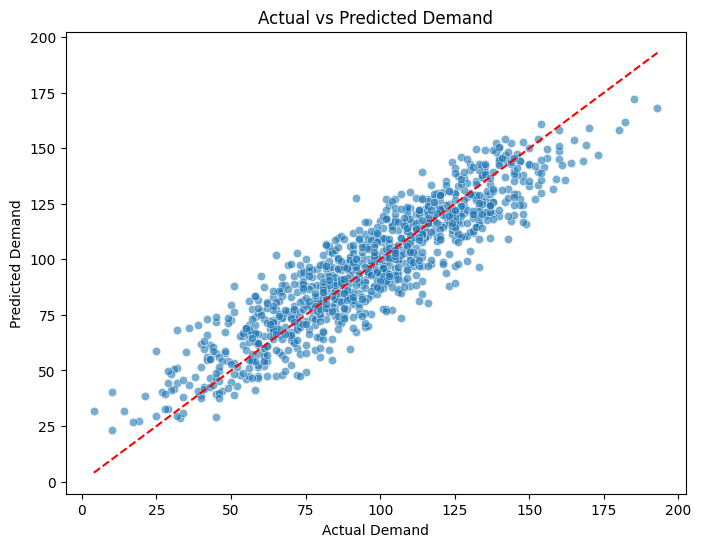

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.title("Actual vs Predicted Demand")
plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")

plt.show()

In [ ]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

importances = model.named_steps["regressor"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
2,num__Previous_Demand,0.497962
1,num__Units_Sold,0.238590
8,num__Month,0.077132
3,num__Discount_Percent,0.071818
6,num__Customer_Rating,0.022100
4,num__Lead_Time_Days,0.017620
0,num__Current_Stock,0.017028
5,num__Delivery_Days,0.008261
9,num__Day_of_Week,0.007459
7,num__Unit_Price,0.006803


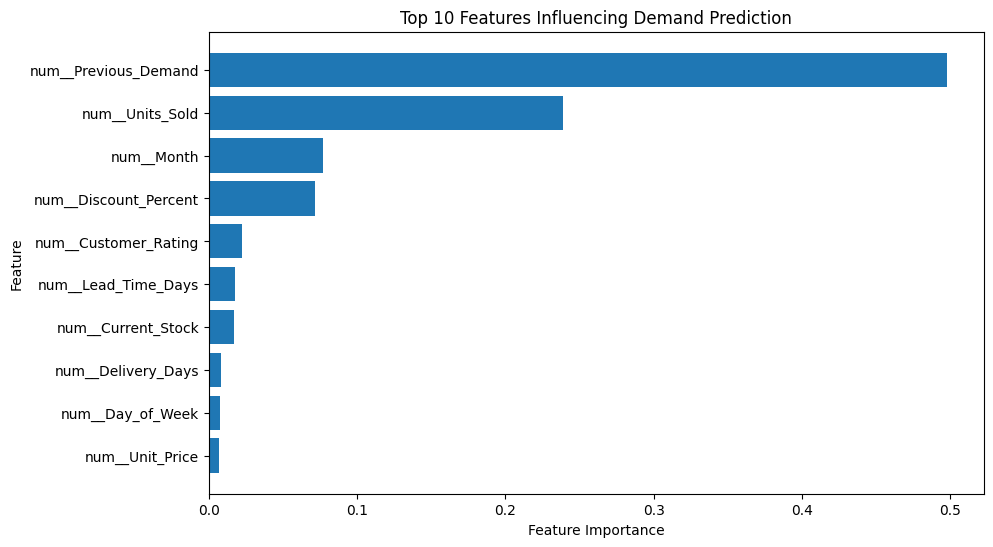

In [ ]:
top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Features Influencing Demand Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()